# Project1 CS-433

**Notes on implementation from project1_description.pdf :**

For SGD, you must use the standard mini-batch-size 1 (sample just one datapoint).
The mean squared error formula has a factor 0.5 to be consistent with the lecture notes. For least squares, you are allowed to use everything from numpy.linalg but not numpy.linalg.lstsq. All vectors should be implemented as 1D arrays with shape (X,) instead of (X, 1).


Return type: Note that all functions should return: (w, loss), which is the last weight vector of the
method, and the corresponding loss value (cost function). Note that while in previous labs you might
have kept track of all encountered w for iterative methods, here we only want the last one. Moreover, the
loss returned by the regularized methods (ridge regression and reg logistic regression) should
not include the penalty term.



## Imports and Loading Data

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from helpers import load_csv_data, create_csv_submission
from implementations import (
    compute_mse_loss,
    negative_log_likelihood,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
)

%load_ext autoreload
%autoreload 2

sns.set_theme()

# one seed for everything random: the data split and the SGD samples
# (implementations.py draws from numpy's global RNG, so np.random.seed covers it)
SEED = 42
np.random.seed(SEED)

data_path = "data/"
# since the dataset is large (328k rows) we subsample first (every 50th row)
# then train on whole dataset once the implementation is validated i.e. set sub_sample = False
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path, sub_sample=True)

In [2]:
print(x_train.shape)
print(x_test.shape)

(6563, 321)
(109379, 321)


## Preprocessing Data

**for logistic regression:**
- Labels: the logistic regression functions expect y in {0, 1}, but load_csv_data gives y in {−1, 1}. Convert first with y01 = (y_train + 1) / 2. Convert back to −1/1 for predictions for the submission. (We don't implement the loss for y in {−1, 1} because then we would fail the tests provided by the course.)
- Feature scaling: some columns hold huge values, for example SEQNO is around 2,015,015,629. Then tx @ w gets very large and np.exp in sigmoid overflows. You'll see RuntimeWarning: overflow and training will behave badly. Standardize the features and handle the NaNs before training. The loss itself is already safe from this because of logaddexp.

**Split:** the labelled data (x_train, y_train) is split 80/10/10 into train / validation / test.
- train: fit the weights and the standardization statistics (mean, std), so no information leaks from the other splits
- validation: pick the hyperparameters (gamma, lambda_) in the sweeps
- test: used only once, in the final comparison, to report train vs. test results

x_test from load_csv_data has no labels, it is only used for the submission (renamed tx_sub after preprocessing).

In [3]:
import warnings

# --- 80/10/10 split of the labelled data into train / validation / test ---
N = len(y_train)
perm = np.random.default_rng(SEED).permutation(N)
n_tr, n_va = int(0.8 * N), int(0.1 * N)
idx_tr, idx_va, idx_te = perm[:n_tr], perm[n_tr : n_tr + n_va], perm[n_tr + n_va :]

# --- standardization statistics from the train split only ---
# columns that are entirely NaN in the train split give nan (numpy warns about it, silenced here)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    mean = np.nanmean(x_train[idx_tr], axis=0)
    std = np.nanstd(x_train[idx_tr], axis=0)
keep = std > 0  # drop constant columns (std = 0, would divide by zero) and all-NaN columns (std = nan)


def preprocess(x):
    """Standardize with the train statistics, replace NaN by 0 (= the train mean
    after standardizing) and add a bias column of ones as first column."""
    x = (x[:, keep] - mean[keep]) / std[keep]
    x = np.nan_to_num(x, nan=0.0)
    return np.c_[np.ones(len(x)), x]


tx_tr, tx_va, tx_te = (preprocess(x_train[idx]) for idx in (idx_tr, idx_va, idx_te))
y_tr, y_va, y_te = y_train[idx_tr], y_train[idx_va], y_train[idx_te]
tx_sub = preprocess(x_test)  # unlabelled, only for the submission

# labels in {0, 1} for the logistic regression functions
y_tr01, y_va01, y_te01 = ((y + 1) / 2 for y in (y_tr, y_va, y_te))

print(f"dropped {np.sum(~keep)} constant / all-NaN columns -> {tx_tr.shape[1]} features (incl. bias)")
print(f"train {tx_tr.shape}  validation {tx_va.shape}  test {tx_te.shape}  submission {tx_sub.shape}")
print(f"positive rate: train {np.mean(y_tr == 1):.3f}  validation {np.mean(y_va == 1):.3f}  test {np.mean(y_te == 1):.3f}")

dropped 13 constant / all-NaN columns -> 309 features (incl. bias)
train (5250, 309)  validation (656, 309)  test (657, 309)  submission (109379, 309)
positive rate: train 0.086  validation 0.081  test 0.084


## Training helpers

The functions in implementations.py only return the final (w, loss). To get the training loss after every epoch without redoing gradient steps, we call them in chunks and warm-start each chunk from the previous w (initial_w = last w). Each update only depends on the current w, so e.g. 10 + 10 iterations give exactly the same w as 20 iterations (for SGD as well, since the RNG is seeded once per run and continues where it left off). The loss returned by each chunk is the training loss at that w.

- GD / logistic regression: 1 epoch = 1 iteration (one full-gradient step over the train set)
- SGD: 1 epoch = N_train iterations (single-sample steps, one pass worth of samples)

Hyperparameters are chosen by sweeps: for each value we train with checkpoints and keep the value with the lowest **validation** loss at the last epoch. The number of epochs is not swept: the training curve shows where it flattens.

In [4]:
def run_with_checkpoints(step, w0, n_epochs, iters_per_epoch=1, seed=SEED):
    """Train in chunks of iters_per_epoch steps, warm-starting each chunk from the last w.

    Args:
        step (callable): step(w, k) -> (w, loss), a function of implementations.py
            with everything fixed except initial_w and max_iters
        w0 (np.ndarray): initial weight vector, shape (D,)
        n_epochs (int): number of chunks
        iters_per_epoch (int): max_iters passed to step for each chunk
        seed (int): seed for the global RNG (used by SGD)

    Returns:
        tuple: (ws, losses) with ws shape (n_epochs + 1, D) the weights after each epoch
            and losses shape (n_epochs + 1,) the training losses (index 0 = at w0)
    """
    np.random.seed(seed)
    w, loss = step(w0, 0)  # 0 iterations: loss at w0
    ws, losses = [w], [loss]
    for _ in range(n_epochs):
        w, loss = step(w, iters_per_epoch)
        ws.append(w)
        losses.append(loss)
        if not np.isfinite(loss):  # diverged, no point in continuing
            break
    return np.array(ws), np.array(losses)


def sweep(make_step, values, w0, n_epochs, iters_per_epoch, val_loss):
    """Train once per hyperparameter value and select the value with the lowest validation loss.

    Args:
        make_step (callable): make_step(value) -> step(w, k), see run_with_checkpoints
        values (list): hyperparameter values to try
        w0, n_epochs, iters_per_epoch: see run_with_checkpoints
        val_loss (callable): val_loss(w) -> validation loss of the final weights

    Returns:
        tuple: (results, best) with results[value] = dict(ws, losses, val_loss)
            and best the value with the lowest finite validation loss
    """
    results = {}
    for v in values:
        # diverging runs overflow on purpose, we detect them through the loss instead
        with np.errstate(over="ignore", invalid="ignore"):
            ws, losses = run_with_checkpoints(make_step(v), w0, n_epochs, iters_per_epoch)
            vl = val_loss(ws[-1])
        results[v] = dict(ws=ws, losses=losses, val_loss=vl)
        print(f"  {v:<8g} train loss {losses[-1]:<12.5g} validation loss {vl:.5g}")
    best = min((v for v in values if np.isfinite(results[v]["val_loss"])),
               key=lambda v: results[v]["val_loss"])
    print(f"best: {best:g}")
    return results, best


def plot_sweep(results, best, title, param="gamma", epoch_label="epoch"):
    """Training loss vs. epoch, one line per hyperparameter value (log scale).
    Runs whose loss ends above its starting value are labelled as diverged."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    colors = sns.color_palette("viridis", len(results))
    for c, (v, r) in zip(colors, results.items()):
        losses = r["losses"]
        finite = np.isfinite(losses)
        diverged = not finite.all() or losses[finite][-1] > losses[0]
        label = f"{param} = {v:g}" + (" (best)" if v == best else "") + (" (diverged)" if diverged else "")
        ax.plot(np.flatnonzero(finite), losses[finite], color=c,
                lw=3 if v == best else 1.5, ls="--" if diverged else "-", label=label)
    ax.set_yscale("log")
    ax.set_ylim(top=2 * results[best]["losses"][0])  # keep diverging runs from squashing the plot
    ax.set(title=title, xlabel=epoch_label, ylabel="training loss")
    ax.legend(fontsize=9)
    plt.show()


def predict(tx, w):
    """Labels in {-1, 1}: sign of x^T w (for logistic regression same as sigma(x^T w) >= 0.5)."""
    return np.where(tx @ w >= 0, 1, -1)


def accuracy(y, y_pred):
    return np.mean(y == y_pred)


def f1_score(y, y_pred):
    """F1 of the positive class (+1). F1 = 2 TP / (2 TP + FP + FN)"""
    tp = np.sum((y_pred == 1) & (y == 1))
    fp = np.sum((y_pred == 1) & (y == -1))
    fn = np.sum((y_pred == -1) & (y == 1))
    return 2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0


w0 = np.zeros(tx_tr.shape[1])

## Mean Squared Error GD

  0.001    train loss 0.36751      validation loss 0.36753


  0.003    train loss 0.23646      validation loss 0.23746


  0.01     train loss 0.1364       validation loss 0.13922


  0.03     train loss 0.12833      validation loss 0.13422


  0.1      train loss 0.12668      validation loss 0.13584
best: 0.03


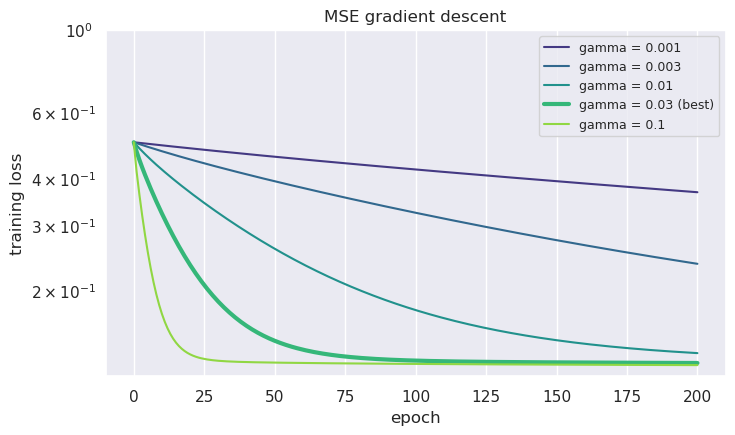

In [5]:
gd_gammas = [0.001, 0.003, 0.01, 0.03, 0.1]
gd_epochs = 200

gd_results, gd_gamma = sweep(
    lambda g: lambda w, k: mean_squared_error_gd(y_tr, tx_tr, w, k, g),
    gd_gammas, w0, gd_epochs, iters_per_epoch=1,
    val_loss=lambda w: compute_mse_loss(y_va, tx_va, w),
)
plot_sweep(gd_results, gd_gamma, "MSE gradient descent")

## Mean Squared Error SGD

  0.0001   train loss 0.13005      validation loss 0.1351


  0.0003   train loss 0.13102      validation loss 0.14017


  0.001    train loss 0.13884      validation loss 0.15219


  0.003    train loss 29231        validation loss 24616
best: 0.0001


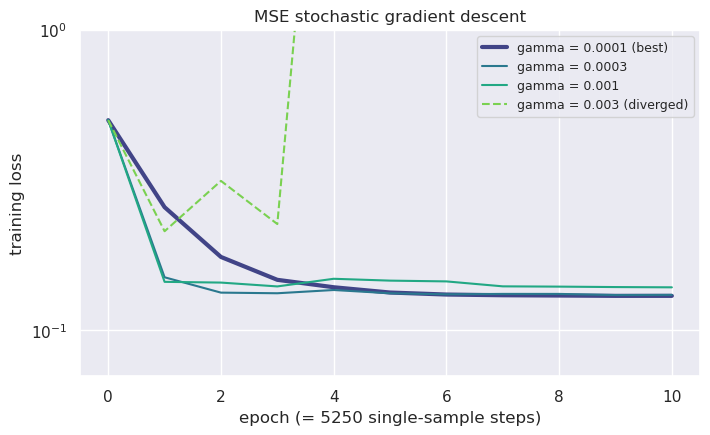

In [6]:
sgd_gammas = [1e-4, 3e-4, 1e-3, 3e-3]
sgd_epochs = 10

sgd_results, sgd_gamma = sweep(
    lambda g: lambda w, k: mean_squared_error_sgd(y_tr, tx_tr, w, k, g),
    sgd_gammas, w0, sgd_epochs, iters_per_epoch=len(y_tr),
    val_loss=lambda w: compute_mse_loss(y_va, tx_va, w),
)
plot_sweep(sgd_results, sgd_gamma, "MSE stochastic gradient descent",
           epoch_label=f"epoch (= {len(y_tr)} single-sample steps)")

## Logistic Regression 

  0.01     train loss 0.4485       validation loss 0.44926


  0.03     train loss 0.3049       validation loss 0.30782


  0.1      train loss 0.22674      validation loss 0.23879


  0.3      train loss 0.2043       validation loss 0.23211


  1        train loss 0.1955       validation loss 0.24156
best: 0.3


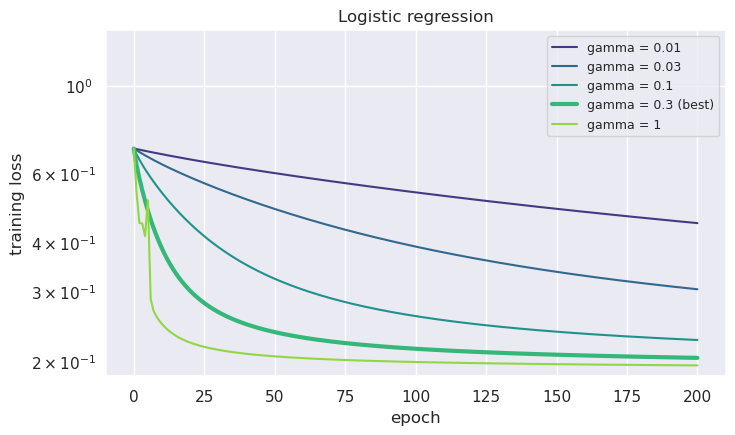

In [7]:
lr_gammas = [0.01, 0.03, 0.1, 0.3, 1.0]
lr_epochs = 200

lr_results, lr_gamma = sweep(
    lambda g: lambda w, k: logistic_regression(y_tr01, tx_tr, w, k, g),
    lr_gammas, w0, lr_epochs, iters_per_epoch=1,
    val_loss=lambda w: negative_log_likelihood(y_va01, tx_va, w),
)
plot_sweep(lr_results, lr_gamma, "Logistic regression")

## Regularized Logistic Regression

We keep the best gamma of logistic regression and sweep lambda_. lambda_ is chosen on the validation loss: the training loss can't be used, since the penalty always makes it larger.

  1e-05    train loss 0.20432      validation loss 0.2321


  0.0001   train loss 0.2045       validation loss 0.23207


  0.001    train loss 0.20636      validation loss 0.23199


  0.01     train loss 0.22963      validation loss 0.24371


  0.1      train loss 0.37389      validation loss 0.3756
best: 0.001


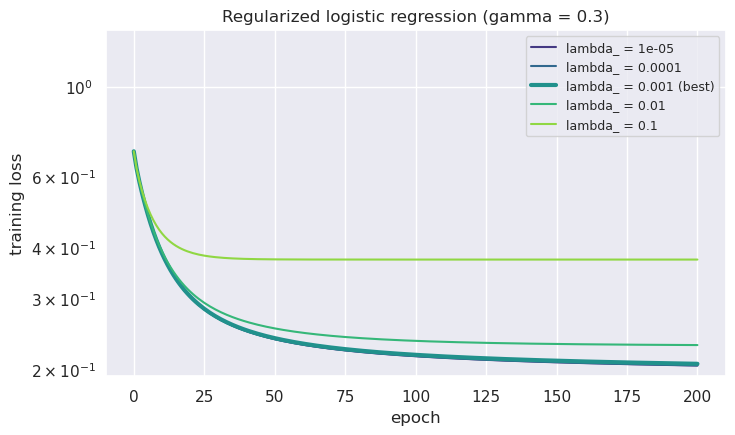

In [8]:
reg_lambdas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
reg_epochs = lr_epochs

reg_results, reg_lambda = sweep(
    lambda lam: lambda w, k: reg_logistic_regression(y_tr01, tx_tr, lam, w, k, lr_gamma),
    reg_lambdas, w0, reg_epochs, iters_per_epoch=1,
    val_loss=lambda w: negative_log_likelihood(y_va01, tx_va, w),
)
plot_sweep(reg_results, reg_lambda, f"Regularized logistic regression (gamma = {lr_gamma:g})",
           param="lambda_")

## Comparison: train vs. test

Best hyperparameters of each method (chosen on the validation set), evaluated once on the train and test splits. Loss is MSE for the MSE methods and the negative log-likelihood for the logistic ones, so losses can only be compared within a family. Accuracy and F1 are comparable across all methods. F1 matters more than accuracy here: only about 8.5% of the labels are positive, so always predicting -1 already gives about 91% accuracy (and F1 = 0).

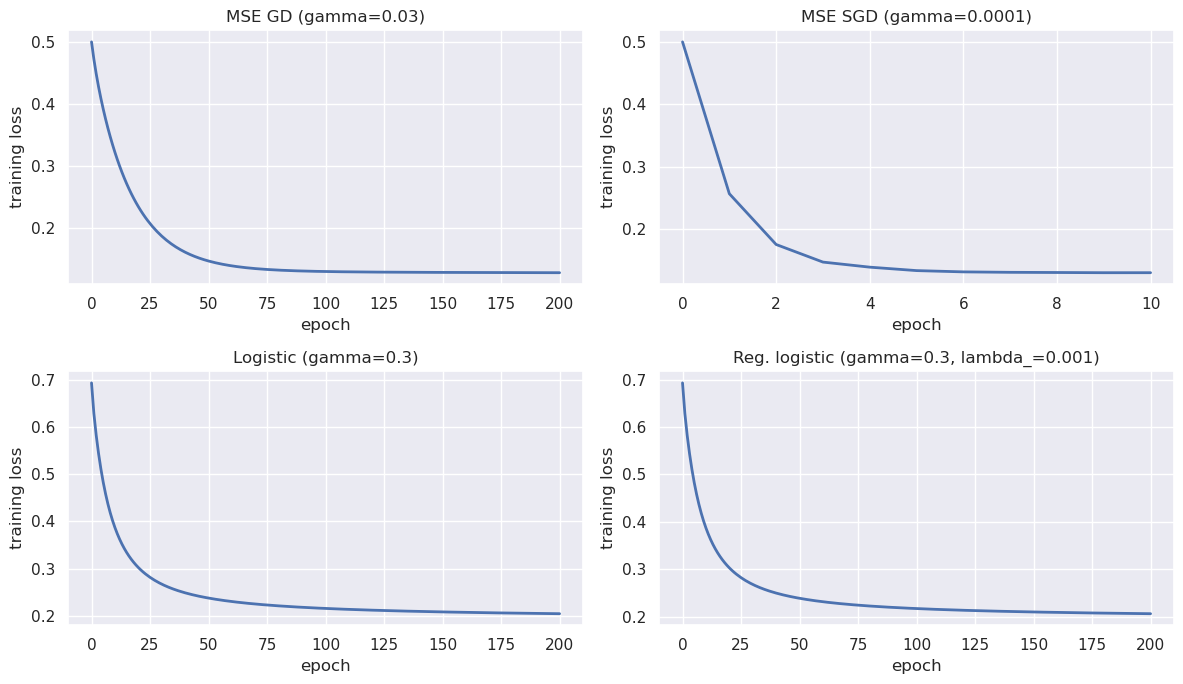

method         split       loss  accuracy      F1
MSE GD         train     0.1283     0.914   0.022
MSE GD         test      0.1407     0.916   0.000
MSE SGD        train     0.1301     0.914   0.009
MSE SGD        test      0.1422     0.915   0.000
Logistic       train     0.2043     0.922   0.279
Logistic       test      0.2472     0.912   0.121
Reg. logistic  train     0.2064     0.922   0.269
Reg. logistic  test      0.2466     0.910   0.063


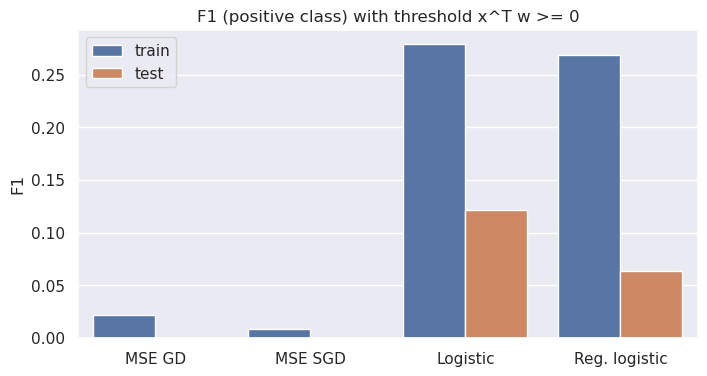

In [9]:
best_runs = {
    # name: (results of the best run, hyperparameters, loss function, train labels, test labels for the loss)
    "MSE GD": (gd_results[gd_gamma], f"gamma={gd_gamma:g}", compute_mse_loss, y_tr, y_te),
    "MSE SGD": (sgd_results[sgd_gamma], f"gamma={sgd_gamma:g}", compute_mse_loss, y_tr, y_te),
    "Logistic": (lr_results[lr_gamma], f"gamma={lr_gamma:g}", negative_log_likelihood, y_tr01, y_te01),
    "Reg. logistic": (reg_results[reg_lambda], f"gamma={lr_gamma:g}, lambda_={reg_lambda:g}",
                      negative_log_likelihood, y_tr01, y_te01),
}

# --- training loss curves of the best run of each method ---
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, (r, params, *_)) in zip(axes.flat, best_runs.items()):
    ax.plot(r["losses"], lw=2)
    ax.set(title=f"{name} ({params})", xlabel="epoch", ylabel="training loss")
fig.tight_layout()
plt.show()

# --- train vs. test table ---
names, splits, f1s = [], [], []
print(f"{'method':<15}{'split':<7}{'loss':>9}{'accuracy':>10}{'F1':>8}")
for name, (r, params, loss_fn, y_loss_tr, y_loss_te) in best_runs.items():
    w = r["ws"][-1]
    for split, tx, y_pm, y_loss in [("train", tx_tr, y_tr, y_loss_tr), ("test", tx_te, y_te, y_loss_te)]:
        y_pred = predict(tx, w)
        f1 = f1_score(y_pm, y_pred)
        print(f"{name:<15}{split:<7}{loss_fn(y_loss, tx, w):>9.4f}{accuracy(y_pm, y_pred):>10.3f}{f1:>8.3f}")
        names.append(name)
        splits.append(split)
        f1s.append(f1)

# --- train vs. test F1 ---
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=names, y=f1s, hue=splits, ax=ax)
ax.set(title="F1 (positive class) with threshold x^T w >= 0", ylabel="F1")
plt.show()

## Generating submission 

In [10]:
# predictions on the unlabelled set with the best regularized logistic regression, in {-1, 1}
w_sub = reg_results[reg_lambda]["ws"][-1]
y_pred_sub = predict(tx_sub, w_sub)
print(f"predicted positive rate on the submission set: {np.mean(y_pred_sub == 1):.3f}")

# uncomment to write the file
# create_csv_submission(test_ids, y_pred_sub, "submission.csv")

predicted positive rate on the submission set: 0.019
